> Run from the cloned repo (Anaconda Jupyter on Windows/Linux/macOS, or Colab after cloning https://github.com/Rishabh-bgp/xai-shap-lime-cnn-bilstm-attention-wind). Install dependencies once with `%pip install -r requirements.txt` (or `%pip install -r ../requirements.txt` from `notebooks/`). The data cell finds the committed synthetic CSV, downloads it from GitHub, or regenerates it.

# Walkthrough: CNN–BiLSTM–Attention + SHAP / LIME / attention
Simplified, CPU-fast version of `src/train_eval.py`. Reimplementation; numbers will differ from the paper.

In [1]:
import os, sys, urllib.request
from pathlib import Path
os.environ.setdefault('OMP_NUM_THREADS', '2')
# repo root = folder containing src/ (works from notebooks/ or repo root, Windows/Linux/Colab)
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / 'src').is_dir()), Path.cwd())
sys.path.insert(0, str(ROOT))
REPO = 'xai-shap-lime-cnn-bilstm-attention-wind'

def find_csv(name):
    """../data -> data -> GitHub raw URL -> regenerate with the seeded generator."""
    for p in [Path.cwd().parent / 'data' / name, Path.cwd() / 'data' / name, ROOT / 'data' / name]:
        if p.exists(): return p
    out = ROOT / 'data' / name; out.parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/Rishabh-bgp/{REPO}/main/data/{name}', out); return out
    except Exception as e:
        print('download failed, regenerating synthetic data:', e)
    if name == 'synthetic_sites.csv':
        from src.sites import synthetic_sites; synthetic_sites(n_hours=24 * 60, seed=0).to_csv(out, index=False)
    else:
        from src.data import synthetic_scada; d = synthetic_scada(24 * 120, seed=0); d.index.name = 'timestamp'; d.to_csv(out)
    return out

import numpy as np, torch, matplotlib.pyplot as plt
torch.manual_seed(0); torch.set_num_threads(2)
print('repo root:', ROOT)

repo root: xai-shap-lime-cnn-bilstm-attention-wind


## 1. Load the committed synthetic SCADA-style CSV
`data/synthetic_scada.csv` is **synthetic** (seeded generator `scripts/make_synthetic.py`), not the confidential original SCADA data.

In [2]:
from src.data import load_scada_csv, add_features, make_windows, chrono_split, Scaler
from src.metrics import regression_metrics
raw = load_scada_csv(find_csv('synthetic_scada.csv'))
raw.head()

,wind_speed,wind_direction,temperature,pressure,humidity,power
timestamp,,,,,,
2018-01-01 00:00:00,5.737794,223.408447,23.940016,1008.144888,79.291828,181.450999
2018-01-01 01:00:00,5.311578,203.414522,25.093541,1008.083422,78.237979,125.660019
2018-01-01 02:00:00,6.098380,187.419159,23.755674,1008.513628,75.607545,246.256732
2018-01-01 03:00:00,5.912926,207.694372,24.992387,1007.578456,73.548041,210.616083
2018-01-01 04:00:00,5.666016,211.785966,24.673154,1008.536566,75.529499,170.637901


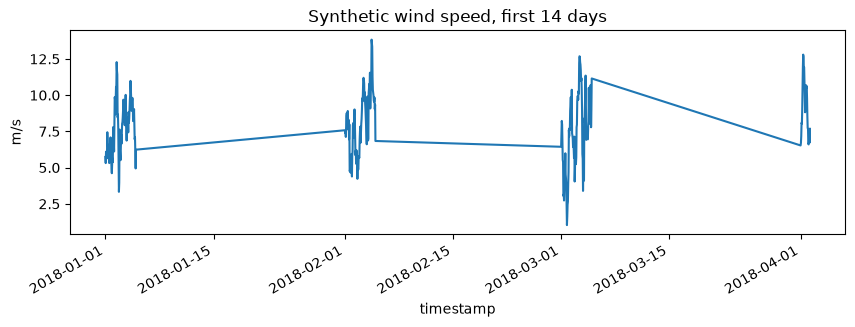

In [3]:
raw['wind_speed'].iloc[:24*14].plot(figsize=(10,3), title='Synthetic wind speed, first 14 days'); plt.ylabel('m/s'); plt.show()

## 2. Windows of 24 wind-speed lags, chronological split, scaling

In [4]:
from src.trainutil import fit, predict
from src.model import CNNBiLSTMAttention
X, y = make_windows(raw[['wind_speed']], lookback=24)
tr, va, te = chrono_split(len(X)); sc = Scaler().fit(X[tr]); Xs = sc.transform(X).astype('float32')
ym, ys = y[tr].mean(), y[tr].std(); yn = ((y-ym)/ys).astype('float32')

## 3. Build and briefly train the model (Conv1D → BiLSTM → soft attention → dense)

In [5]:
model = fit(CNNBiLSTMAttention(1), Xs[tr], yn[tr], Xs[va], yn[va], epochs=4)
pred = predict(model, Xs[te])*ys + ym
print('model      ', regression_metrics(y[te], pred))
print('persistence', regression_metrics(y[te], X[te][:, -1, 0]))

model       {'MAE': 1.2275562352604337, 'RMSE': 1.5453693334103875, 'MAPE_%': 15.367804906665816, 'R2': 0.5768633315924274}
persistence {'MAE': 0.7786463048723009, 'RMSE': 1.0788346983033934, 'MAPE_%': 10.084407356304313, 'R2': 0.7937823207879058}


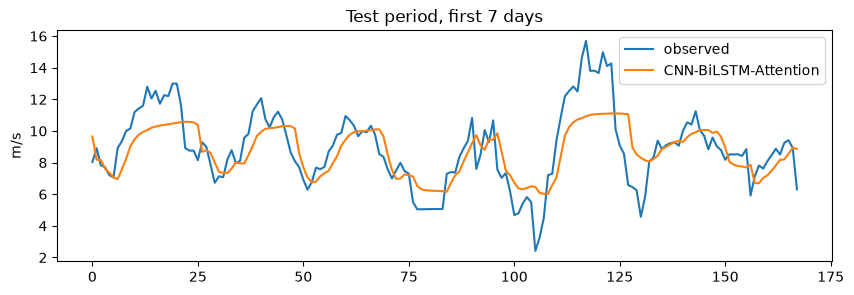

In [6]:
plt.figure(figsize=(10,3)); plt.plot(y[te][:168], label='observed'); plt.plot(pred[:168], label='CNN-BiLSTM-Attention'); plt.legend(); plt.ylabel('m/s'); plt.title('Test period, first 7 days'); plt.show()

## 4. Explain: attention weights vs SHAP (GradientExplainer)

<site-packages>/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


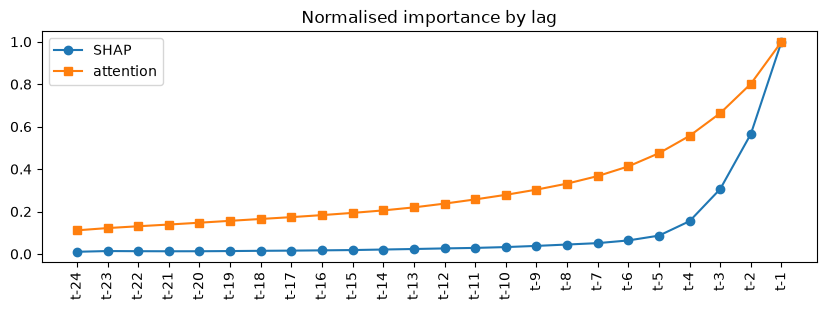

In [7]:
import shap
predict(model, Xs[te][:100]); att = model.last_attention.numpy().mean(0)
wrapped = torch.nn.Sequential(model, torch.nn.Unflatten(0, (-1, 1)))
sv = np.asarray(shap.GradientExplainer(wrapped, torch.tensor(Xs[tr][:100])).shap_values(torch.tensor(Xs[te][:100]))).reshape(100, 24)
imp = np.abs(sv).mean(0)
lags = [f't-{24-i}' for i in range(24)]
plt.figure(figsize=(10,3)); plt.plot(lags, imp/imp.max(), 'o-', label='SHAP'); plt.plot(lags, att/att.max(), 's-', label='attention'); plt.xticks(rotation=90); plt.legend(); plt.title('Normalised importance by lag'); plt.show()